# SHL Hiring Assessment 2026 — Spoken Grammar Scoring

## My Final Submission Notebook

In this notebook, I build a Grammar Scoring Engine for spoken English audio.

My goal is to predict a continuous grammar score from **0 to 5** for every test audio file.

### Dataset

- Training samples: **769**
- Test samples: **216**
- Input: spoken `.wav` audio
- Target: `label`

### My approach

I combine speech, text, acoustic, grammar, and transcription-quality information instead of relying on a single model.

My final pipeline contains:

1. WavLM-Large speech representations
2. WavLM-Base speech representations
3. Whisper-medium encoder representations
4. Whisper-medium transcripts
5. MPNet and DeBERTa text representations
6. Acoustic features
7. Explicit grammar/text features
8. Whisper transcription-quality features
9. Ridge, ExtraTrees, and LightGBM models
10. A final weighted ensemble

I use out-of-fold predictions for the training evaluation so that the reported validation result is more meaningful than an in-sample score.



## 1. Kaggle Runtime Requirements

Run this notebook on Kaggle with:

- **GPU accelerator enabled**
- **Internet enabled** for Hugging Face model downloads and LanguageTool initialization
- The competition dataset attached as an input


In [131]:
# ============================================================
# Cell 1 — Imports, configuration, and reproducibility
# ============================================================

import os
import gc
import re
import math
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import librosa
import soundfile as sf
import matplotlib.pyplot as plt

import torch

from tqdm.auto import tqdm

from sklearn.model_selection import KFold
from sklearn.linear_model import Ridge
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_squared_error
from scipy.stats import pearsonr

from lightgbm import LGBMRegressor

warnings.filterwarnings("ignore")

SEED = 2026

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

BASE = Path("/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final")
TRAIN_DIR = BASE / "train"
TEST_DIR = BASE / "test"
CACHE_DIR = Path("/kaggle/working")
CACHE_DIR.mkdir(parents=True, exist_ok=True)

print("Device:", DEVICE)
if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
print("Dataset:", BASE)

Device: cuda
GPU: Tesla T4
Dataset: /kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final


In [132]:
# ============================================================
# Cell 2 — Load dataset and perform sanity checks
# ============================================================

train_df = pd.read_csv(BASE / "train.csv")
test_df = pd.read_csv(BASE / "test.csv")
sample_submission = pd.read_csv(BASE / "sample_submission.csv")

y = train_df["label"].astype(np.float64).to_numpy()

def wav_path(directory, filename):
    filename = str(filename)
    if not filename.lower().endswith(".wav"):
        filename = filename + ".wav"
    return directory / filename

missing_train = sum(
    not wav_path(TRAIN_DIR, f).exists()
    for f in train_df["filename"]
)

missing_test = sum(
    not wav_path(TEST_DIR, f).exists()
    for f in test_df["filename"]
)

print("Train shape:", train_df.shape)
print("Test shape :", test_df.shape)
print("Sample submission shape:", sample_submission.shape)
print("Missing train audio:", missing_train)
print("Missing test audio :", missing_test)
print("Target range:", float(y.min()), "to", float(y.max()))

assert len(train_df) == 769
assert len(test_df) == 216
assert missing_train == 0
assert missing_test == 0
assert {"filename", "label"}.issubset(train_df.columns)
assert {"filename"}.issubset(test_df.columns)

print("\n✓ Dataset checks passed.")

Train shape: (769, 2)
Test shape : (216, 2)
Sample submission shape: (204, 2)
Missing train audio: 0
Missing test audio : 0
Target range: 0.0 to 5.0

✓ Dataset checks passed.


In [133]:
# ============================================================
# Cell 3 — Cache utilities
# ============================================================

def cache_path(name):
    return CACHE_DIR / name

def cache_exists(name):
    return cache_path(name).exists()

def save_npy(name, array):
    np.save(cache_path(name), np.asarray(array))

def load_npy(name):
    return np.load(cache_path(name))

def save_csv(name, df):
    df.to_csv(cache_path(name), index=False)

print("Cache directory:", CACHE_DIR)

Cache directory: /kaggle/working


## 2. Audio Transcription and Whisper Quality Features

The transcript branch is created with **Whisper-medium** using `faster-whisper`. Audio is decoded with `librosa` and passed to Whisper as a NumPy array, which avoids PyAV file-decoding incompatibilities in some Kaggle runtimes.

The transcription stage uses the complete recording. Along with the transcript, segment and word timing statistics are extracted to quantify:

- transcription confidence,
- silence / pause structure,
- speech coverage,
- unusually long pauses,
- decoder quality indicators.

In [134]:
# ============================================================
# Cell 4 — Whisper transcription + 10 quality features
# ============================================================

from faster_whisper import WhisperModel

WHISPER_CACHE_TRAIN = "train_texts.csv"
WHISPER_CACHE_TEST = "test_texts.csv"
QUALITY_CACHE_TRAIN = "quality_train.npy"
QUALITY_CACHE_TEST = "quality_test.npy"

whisper_device = "cuda" if torch.cuda.is_available() else "cpu"
whisper_compute = "float16" if whisper_device == "cuda" else "int8"

print("Loading faster-whisper medium...")

whisper_model = WhisperModel(
    "medium",
    device=whisper_device,
    compute_type=whisper_compute
)


def transcribe_with_quality(audio_path):
    """
    Load the WAV file with librosa and pass the NumPy audio array
    directly to faster-whisper.

    Passing the file path directly can trigger a PyAV compatibility
    error in some Kaggle environments:
        open() got an unexpected keyword argument 'metadata_errors'

    Using a NumPy array avoids PyAV file decoding completely.
    """

    audio, sr = librosa.load(
        audio_path,
        sr=16000,
        mono=True
    )

    audio = np.asarray(
        audio,
        dtype=np.float32
    )

    segments, info = whisper_model.transcribe(
        audio,
        language="en",
        task="transcribe",
        beam_size=5,
        vad_filter=True,
        word_timestamps=True
    )

    segments = list(segments)

    text_parts = []
    avg_logprobs = []
    no_speech = []
    compression = []

    all_words = []

    for seg in segments:
        text_parts.append(
            seg.text.strip()
        )

        if seg.avg_logprob is not None:
            avg_logprobs.append(
                float(seg.avg_logprob)
            )

        if seg.no_speech_prob is not None:
            no_speech.append(
                float(seg.no_speech_prob)
            )

        if seg.compression_ratio is not None:
            compression.append(
                float(seg.compression_ratio)
            )

        if seg.words:
            for word in seg.words:
                if (
                    word.start is not None
                    and word.end is not None
                ):
                    all_words.append(
                        (
                            float(word.start),
                            float(word.end)
                        )
                    )

    text = " ".join(
        t for t in text_parts if t
    ).strip()

    starts = [
        float(seg.start)
        for seg in segments
        if seg.start is not None
    ]

    ends = [
        float(seg.end)
        for seg in segments
        if seg.end is not None
    ]

    speech_seconds = float(
        sum(
            max(
                0.0,
                float(seg.end) - float(seg.start)
            )
            for seg in segments
            if (
                seg.start is not None
                and seg.end is not None
            )
        )
    )

    if starts and ends:
        span = float(
            max(ends) - min(starts)
        )
    else:
        span = speech_seconds

    pauses = []

    if len(all_words) >= 2:
        all_words = sorted(
            all_words,
            key=lambda x: x[0]
        )

        for (_, prev_end), (next_start, _) in zip(
            all_words[:-1],
            all_words[1:]
        ):
            gap = max(
                0.0,
                next_start - prev_end
            )

            if gap > 0:
                pauses.append(gap)

    if pauses:
        pause_mean = float(
            np.mean(pauses)
        )

        pause_p90 = float(
            np.percentile(
                pauses,
                90
            )
        )

        pause_max = float(
            np.max(pauses)
        )

        long_pause_rate = float(
            np.mean(
                np.asarray(pauses) >= 1.0
            )
        )

        pause_total = float(
            np.sum(pauses)
        )

    else:
        pause_mean = 0.0
        pause_p90 = 0.0
        pause_max = 0.0
        long_pause_rate = 0.0
        pause_total = 0.0

    pause_ratio = (
        pause_total / span
        if span > 0
        else 0.0
    )

    quality = np.array(
        [
            (
                np.mean(avg_logprobs)
                if avg_logprobs
                else -1.0
            ),
            (
                np.mean(no_speech)
                if no_speech
                else 0.0
            ),
            (
                np.mean(compression)
                if compression
                else 0.0
            ),
            speech_seconds,
            span,
            pause_mean,
            pause_p90,
            pause_max,
            long_pause_rate,
            pause_ratio
        ],
        dtype=np.float32
    )

    return text, quality


def build_transcripts_and_quality(
    df,
    directory,
    text_cache,
    quality_cache
):
    if (
        cache_exists(text_cache)
        and cache_exists(quality_cache)
    ):
        texts = pd.read_csv(
            cache_path(text_cache)
        )["text"].fillna("").tolist()

        quality = load_npy(
            quality_cache
        )

        print(
            "Loaded cached:",
            text_cache,
            quality_cache
        )

        return texts, quality

    texts = []
    quality_rows = []

    for filename in tqdm(
        df["filename"],
        desc=f"Whisper: {directory.name}"
    ):
        text, quality = transcribe_with_quality(
            wav_path(
                directory,
                filename
            )
        )

        texts.append(text)
        quality_rows.append(quality)

    quality = np.vstack(
        quality_rows
    ).astype(np.float32)

    pd.DataFrame(
        {
            "filename": df["filename"],
            "text": texts
        }
    ).to_csv(
        cache_path(text_cache),
        index=False
    )

    save_npy(
        quality_cache,
        quality
    )

    return texts, quality


train_texts, X_quality_train = (
    build_transcripts_and_quality(
        train_df,
        TRAIN_DIR,
        WHISPER_CACHE_TRAIN,
        QUALITY_CACHE_TRAIN
    )
)

test_texts, X_quality_test = (
    build_transcripts_and_quality(
        test_df,
        TEST_DIR,
        WHISPER_CACHE_TEST,
        QUALITY_CACHE_TEST
    )
)

print(
    "Train transcripts:",
    len(train_texts)
)

print(
    "Test transcripts :",
    len(test_texts)
)

print(
    "Quality train:",
    X_quality_train.shape
)

print(
    "Quality test :",
    X_quality_test.shape
)

assert X_quality_train.shape == (769, 10)
assert X_quality_test.shape == (216, 10)

del whisper_model

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

Loading faster-whisper medium...
Loaded cached: train_texts.csv quality_train.npy
Loaded cached: test_texts.csv quality_test.npy
Train transcripts: 769
Test transcripts : 216
Quality train: (769, 10)
Quality test : (216, 10)


## 3. Acoustic Features

The acoustic block contains **37 compact features**:

- duration,
- RMS energy statistics,
- zero-crossing statistics,
- spectral centroid,
- spectral bandwidth,
- spectral rolloff,
- mean and standard deviation of 13 MFCC coefficients.

Duration is deliberately kept here because it is useful for the rich LightGBM branch, while the separate ExtraTrees branch later uses an explicit **duration-free** version.

In [135]:
# ============================================================
# Cell 5 — 37 acoustic features
# ============================================================

def acoustic_features(audio_path, sr=16000):
    audio, _ = librosa.load(audio_path, sr=sr, mono=True)

    duration = len(audio) / sr

    rms = librosa.feature.rms(y=audio)[0]
    zcr = librosa.feature.zero_crossing_rate(audio)[0]
    centroid = librosa.feature.spectral_centroid(y=audio, sr=sr)[0]
    bandwidth = librosa.feature.spectral_bandwidth(y=audio, sr=sr)[0]
    rolloff = librosa.feature.spectral_rolloff(y=audio, sr=sr)[0]
    mfcc = librosa.feature.mfcc(
        y=audio,
        sr=sr,
        n_mfcc=13
    )

    features = [
        duration,

        float(np.mean(rms)),
        float(np.std(rms)),

        float(np.mean(zcr)),
        float(np.std(zcr)),

        float(np.mean(centroid)),
        float(np.std(centroid)),

        float(np.mean(bandwidth)),
        float(np.std(bandwidth)),

        float(np.mean(rolloff)),
        float(np.std(rolloff))
    ]

    features.extend(np.mean(mfcc, axis=1).tolist())
    features.extend(np.std(mfcc, axis=1).tolist())

    return np.asarray(features, dtype=np.float32)


def build_acoustic_features(df, directory, cache_name):
    if cache_exists(cache_name):
        return load_npy(cache_name)

    rows = []

    for filename in tqdm(
        df["filename"],
        desc=f"Acoustic: {directory.name}"
    ):
        rows.append(
            acoustic_features(
                wav_path(directory, filename)
            )
        )

    X = np.vstack(rows).astype(np.float32)
    save_npy(cache_name, X)
    return X


X_acoustic_train = build_acoustic_features(
    train_df,
    TRAIN_DIR,
    "acoustic_train.npy"
)

X_acoustic_test = build_acoustic_features(
    test_df,
    TEST_DIR,
    "acoustic_test.npy"
)

print("Acoustic train:", X_acoustic_train.shape)
print("Acoustic test :", X_acoustic_test.shape)

assert X_acoustic_train.shape == (769, 37)
assert X_acoustic_test.shape == (216, 37)

Acoustic train: (769, 37)
Acoustic test : (216, 37)


## 4. Grammar and Text Features

The text block contains **21 features**:

### Basic transcript features — 8
Word count, sentence count, unique-word count, average sentence length, type-token ratio, filler count, repeated-word count, and words-per-minute.

### LanguageTool features — 12
Grammar, spelling, style, punctuation, sentence-level error behavior, error density and error-length statistics.

### CoLA acceptability score — 1
A pretrained grammatical acceptability model provides an additional syntax-oriented signal.

In [136]:
# ============================================================
# Cell 6 — 21 grammar/text features
# ============================================================

import language_tool_python
from transformers import AutoTokenizer, AutoModelForSequenceClassification

FILLERS = {
    "um", "uh", "erm", "hmm", "like", "you know",
    "actually", "basically", "so", "well"
}

language_tool = language_tool_python.LanguageTool("en-US")

cola_tokenizer = AutoTokenizer.from_pretrained(
    "textattack/roberta-base-CoLA"
)

cola_model = AutoModelForSequenceClassification.from_pretrained(
    "textattack/roberta-base-CoLA"
).to(DEVICE).eval()


def basic_text_features(text, speech_seconds):
    text = str(text).strip()

    words = re.findall(r"\b[\w']+\b", text.lower())
    sentences = [
        s.strip()
        for s in re.split(r"[.!?]+", text)
        if s.strip()
    ]

    word_count = len(words)
    sentence_count = max(len(sentences), 1)
    unique_count = len(set(words))

    avg_sentence_length = (
        word_count / sentence_count
    )

    type_token_ratio = (
        unique_count / max(word_count, 1)
    )

    filler_count = sum(
        1 for w in words if w in FILLERS
    )

    repeated_count = sum(
        1
        for a, b in zip(words[:-1], words[1:])
        if a == b
    )

    speaking_minutes = max(
        float(speech_seconds) / 60.0,
        1e-6
    )

    wpm = word_count / speaking_minutes

    return [
        word_count,
        sentence_count,
        unique_count,
        avg_sentence_length,
        type_token_ratio,
        filler_count,
        repeated_count,
        wpm
    ]


def languagetool_features(text):
    matches = language_tool.check(text)

    word_count = max(
        len(re.findall(r"\b[\w']+\b", text.lower())),
        1
    )

    sentences = [
        s for s in re.split(r"[.!?]+", text)
        if s.strip()
    ]
    sentence_count = max(len(sentences), 1)

    issue_types = [
        str(getattr(m, "ruleIssueType", "")).lower()
        for m in matches
    ]

    grammar_count = sum(
        t == "grammar"
        for t in issue_types
    )

    spelling_count = sum(
        t == "misspelling"
        for t in issue_types
    )

    style_count = sum(
        t == "style"
        for t in issue_types
    )

    punctuation_count = sum(
        t == "typographical"
        for t in issue_types
    )

    lengths = np.asarray(
        [
            float(getattr(m, "errorLength", 0))
            for m in matches
        ],
        dtype=np.float32
    )

    replacements = []
    for m in matches:
        repl = getattr(m, "replacements", []) or []
        replacements.append(len(repl))

    replacement_mean = (
        float(np.mean(replacements))
        if replacements
        else 0.0
    )

    error_lengths_mean = (
        float(np.mean(lengths))
        if len(lengths)
        else 0.0
    )

    error_lengths_max = (
        float(np.max(lengths))
        if len(lengths)
        else 0.0
    )

    error_lengths_std = (
        float(np.std(lengths))
        if len(lengths)
        else 0.0
    )

    # Approximate sentence-with-errors count from character offsets.
    sentences_with_errors = set()

    sentence_spans = []
    cursor = 0

    for sent in re.split(r"[.!?]+", text):
        if sent.strip():
            start = text.find(sent, cursor)
            end = start + len(sent)
            sentence_spans.append((start, end))
            cursor = end

    for m in matches:
        offset = int(getattr(m, "offset", 0))
        for idx, (start, end) in enumerate(sentence_spans):
            if start <= offset <= end:
                sentences_with_errors.add(idx)
                break

    return [
        len(matches),
        len(matches) / word_count,
        len(matches) / sentence_count,
        grammar_count,
        spelling_count,
        style_count,
        punctuation_count,
        len(sentences_with_errors),
        error_lengths_mean,
        replacement_mean,
        error_lengths_max,
        error_lengths_std
    ]


@torch.no_grad()
def cola_score(text):
    encoded = cola_tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=256,
        padding=True
    )

    encoded = {
        k: v.to(DEVICE)
        for k, v in encoded.items()
    }

    logits = cola_model(**encoded).logits
    probs = torch.softmax(logits, dim=-1)

    if probs.shape[-1] == 2:
        return float(probs[0, 1].item())

    return float(
        torch.sigmoid(logits[0, 0]).item()
    )


def build_grammar_matrix(
    texts,
    quality_matrix,
    cache_name
):
    if cache_exists(cache_name):
        return load_npy(cache_name)

    rows = []

    # Column 3 = speech_seconds in X_quality
    speech_seconds = quality_matrix[:, 3]

    for text, speech_sec in tqdm(
        zip(texts, speech_seconds),
        total=len(texts),
        desc="Grammar features"
    ):
        row = []
        row.extend(
            basic_text_features(
                text,
                speech_sec
            )
        )
        row.extend(
            languagetool_features(text)
        )
        row.append(
            cola_score(text)
        )
        rows.append(row)

    X = np.asarray(
        rows,
        dtype=np.float32
    )

    save_npy(
        cache_name,
        X
    )

    return X


X_grammar_train = build_grammar_matrix(
    train_texts,
    X_quality_train,
    "grammar_train.npy"
)

X_grammar_test = build_grammar_matrix(
    test_texts,
    X_quality_test,
    "grammar_test.npy"
)

print("Grammar train:", X_grammar_train.shape)
print("Grammar test :", X_grammar_test.shape)

assert X_grammar_train.shape == (769, 21)
assert X_grammar_test.shape == (216, 21)

del cola_model
del cola_tokenizer

language_tool.close()

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: textattack/roberta-base-CoLA
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.weight | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Grammar train: (769, 21)
Grammar test : (216, 21)


## 5. Deep Speech and Text Representations

The final high-dimensional representation is designed to capture complementary information.

| Representation | Dimension |
|---|---:|
| WavLM-Large mean + std | 2048 |
| WavLM-Base mean + std | 1536 |
| MPNet transcript embedding | 768 |
| DeBERTa-v3-large transcript embedding | 1024 |
| Whisper-medium encoder mean + std | 2048 |
| **Total** | **7424** |


In [137]:
# ============================================================
# Cell 7 — WavLM extractor
# ============================================================

from transformers import AutoFeatureExtractor, AutoModel

def extract_wavlm(
    audio_paths,
    model_name,
    cache_name,
    chunk_seconds=15,
    max_seconds=60
):
    if cache_exists(cache_name):
        print("Loaded cached:", cache_name)
        return load_npy(cache_name)

    feature_extractor = AutoFeatureExtractor.from_pretrained(
        model_name
    )

    model = AutoModel.from_pretrained(
        model_name
    ).to(DEVICE).eval()

    if DEVICE == "cuda":
        model = model.half()

    rows = []

    for audio_path in tqdm(
        audio_paths,
        desc=model_name
    ):
        audio, sr = librosa.load(
            audio_path,
            sr=16000,
            mono=True
        )

        audio = audio[: int(max_seconds * sr)]

        chunk_size = int(chunk_seconds * sr)
        chunk_features = []

        for start in range(0, len(audio), chunk_size):
            chunk = audio[start:start + chunk_size]

            if len(chunk) < sr:
                continue

            inputs = feature_extractor(
                chunk,
                sampling_rate=sr,
                return_tensors="pt",
                padding=True
            )

            inputs = {
                k: v.to(DEVICE)
                for k, v in inputs.items()
            }

            if DEVICE == "cuda":
                inputs["input_values"] = (
                    inputs["input_values"]
                    .to(model.dtype)
                )

            with torch.no_grad():
                hidden = model(
                    **inputs
                ).last_hidden_state

            mean = hidden.mean(dim=1)
            std = hidden.std(dim=1)

            pooled = torch.cat(
                [mean, std],
                dim=-1
            )

            chunk_features.append(
                pooled.float().cpu().numpy()[0]
            )

            del hidden
            del inputs

        if not chunk_features:
            chunk = audio

            inputs = feature_extractor(
                chunk,
                sampling_rate=sr,
                return_tensors="pt",
                padding=True
            )

            inputs = {
                k: v.to(DEVICE)
                for k, v in inputs.items()
            }

            if DEVICE == "cuda":
                inputs["input_values"] = (
                    inputs["input_values"]
                    .to(model.dtype)
                )

            with torch.no_grad():
                hidden = model(
                    **inputs
                ).last_hidden_state

            pooled = np.concatenate([
                hidden.mean(dim=1).float().cpu().numpy()[0],
                hidden.std(dim=1).float().cpu().numpy()[0]
            ])

            chunk_features = [pooled]

        rows.append(
            np.mean(
                np.vstack(chunk_features),
                axis=0
            )
        )

    X = np.vstack(rows).astype(np.float32)
    save_npy(cache_name, X)

    del model
    del feature_extractor
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return X


train_audio_paths = [
    wav_path(TRAIN_DIR, f)
    for f in train_df["filename"]
]

test_audio_paths = [
    wav_path(TEST_DIR, f)
    for f in test_df["filename"]
]

wavlm_large_train = extract_wavlm(
    train_audio_paths,
    "microsoft/wavlm-large",
    "wavlm_large_train.npy"
)

wavlm_large_test = extract_wavlm(
    test_audio_paths,
    "microsoft/wavlm-large",
    "wavlm_large_test.npy"
)

wavlm_base_train = extract_wavlm(
    train_audio_paths,
    "microsoft/wavlm-base",
    "wavlm_base_train.npy"
)

wavlm_base_test = extract_wavlm(
    test_audio_paths,
    "microsoft/wavlm-base",
    "wavlm_base_test.npy"
)

print("WavLM-Large:", wavlm_large_train.shape, wavlm_large_test.shape)
print("WavLM-Base :", wavlm_base_train.shape, wavlm_base_test.shape)

Loaded cached: wavlm_large_train.npy
Loaded cached: wavlm_large_test.npy
Loaded cached: wavlm_base_train.npy
Loaded cached: wavlm_base_test.npy
WavLM-Large: (769, 2048) (216, 2048)
WavLM-Base : (769, 1536) (216, 1536)


In [138]:
# ============================================================
# Cell 8 — Text embeddings: MPNet + DeBERTa-v3-large
# ============================================================

from transformers import AutoTokenizer, AutoModel

def mean_pool(last_hidden_state, attention_mask):
    mask = attention_mask.unsqueeze(-1).expand(
        last_hidden_state.size()
    ).float()

    summed = torch.sum(
        last_hidden_state * mask,
        dim=1
    )

    counts = torch.clamp(
        mask.sum(dim=1),
        min=1e-9
    )

    return summed / counts


def embed_texts(
    texts,
    model_name,
    cache_name,
    batch_size=16,
    max_length=256
):
    if cache_exists(cache_name):
        print("Loaded cached:", cache_name)
        return load_npy(cache_name)

    tokenizer = AutoTokenizer.from_pretrained(
        model_name
    )

    model = AutoModel.from_pretrained(
        model_name
    ).to(DEVICE).eval()

    rows = []

    for i in tqdm(
        range(0, len(texts), batch_size),
        desc=model_name
    ):
        batch = texts[i:i + batch_size]

        encoded = tokenizer(
            batch,
            padding=True,
            truncation=True,
            max_length=max_length,
            return_tensors="pt"
        )

        encoded = {
            k: v.to(DEVICE)
            for k, v in encoded.items()
        }

        with torch.no_grad():
            output = model(**encoded)

        pooled = mean_pool(
            output.last_hidden_state,
            encoded["attention_mask"]
        )

        rows.append(
            pooled.float().cpu().numpy()
        )

        del output
        del encoded

    X = np.vstack(rows).astype(np.float32)
    save_npy(cache_name, X)

    del model
    del tokenizer
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return X


mpnet_train = embed_texts(
    train_texts,
    "sentence-transformers/all-mpnet-base-v2",
    "mpnet_train.npy",
    batch_size=16,
    max_length=256
)

mpnet_test = embed_texts(
    test_texts,
    "sentence-transformers/all-mpnet-base-v2",
    "mpnet_test.npy",
    batch_size=16,
    max_length=256
)

deberta_train = embed_texts(
    train_texts,
    "microsoft/deberta-v3-large",
    "deberta_train.npy",
    batch_size=4,
    max_length=256
)

deberta_test = embed_texts(
    test_texts,
    "microsoft/deberta-v3-large",
    "deberta_test.npy",
    batch_size=4,
    max_length=256
)

print("MPNet   :", mpnet_train.shape, mpnet_test.shape)
print("DeBERTa :", deberta_train.shape, deberta_test.shape)

Loaded cached: mpnet_train.npy
Loaded cached: mpnet_test.npy
Loaded cached: deberta_train.npy
Loaded cached: deberta_test.npy
MPNet   : (769, 768) (216, 768)
DeBERTa : (769, 1024) (216, 1024)


In [139]:
# ============================================================
# Cell 9 — Whisper-medium encoder representation
# ============================================================

from transformers import WhisperProcessor, WhisperModel

def extract_whisper_repr(
    audio_paths,
    cache_name
):
    if cache_exists(cache_name):
        print("Loaded cached:", cache_name)
        return load_npy(cache_name)

    processor = WhisperProcessor.from_pretrained(
        "openai/whisper-medium"
    )

    model = WhisperModel.from_pretrained(
        "openai/whisper-medium"
    ).to(DEVICE).eval()

    if DEVICE == "cuda":
        model = model.half()

    encoder = model.get_encoder()
    rows = []

    max_samples = 30 * 16000

    for audio_path in tqdm(
        audio_paths,
        desc="Whisper-medium encoder"
    ):
        audio, _ = librosa.load(
            audio_path,
            sr=16000,
            mono=True
        )

        inputs = processor(
            audio,
            sampling_rate=16000,
            return_tensors="pt",
            padding="max_length",
            max_length=max_samples,
            truncation=True
        )

        input_features = inputs.input_features.to(DEVICE)

        if DEVICE == "cuda":
            input_features = input_features.to(
                dtype=model.dtype
            )

        with torch.no_grad():
            hidden = encoder(
                input_features
            ).last_hidden_state

        pooled = torch.cat([
            hidden.mean(dim=1),
            hidden.std(dim=1)
        ], dim=-1)

        rows.append(
            pooled.float().cpu().numpy()[0]
        )

        del hidden
        del input_features

    X = np.vstack(rows).astype(np.float32)
    save_npy(cache_name, X)

    del encoder
    del model
    del processor

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return X


whisper_repr_train = extract_whisper_repr(
    train_audio_paths,
    "whisper_repr_train.npy"
)

whisper_repr_test = extract_whisper_repr(
    test_audio_paths,
    "whisper_repr_test.npy"
)

print(
    "Whisper representation:",
    whisper_repr_train.shape,
    whisper_repr_test.shape
)

assert whisper_repr_train.shape[1] == 2048
assert whisper_repr_test.shape[1] == 2048

Loaded cached: whisper_repr_train.npy
Loaded cached: whisper_repr_test.npy
Whisper representation: (769, 2048) (216, 2048)


## 6. Build the 7,424-Dimensional Representation

This cell is intentionally explicit because the downstream Ridge models depend on the exact feature dimensions.

In [140]:
# ============================================================
# Cell 10 — Combine all deep representations
# ============================================================

print("Individual representations:")
print("WavLM-Large:", wavlm_large_train.shape, wavlm_large_test.shape)
print("WavLM-Base :", wavlm_base_train.shape, wavlm_base_test.shape)
print("MPNet      :", mpnet_train.shape, mpnet_test.shape)
print("DeBERTa    :", deberta_train.shape, deberta_test.shape)
print("Whisper    :", whisper_repr_train.shape, whisper_repr_test.shape)

deep_train = np.hstack([
    wavlm_large_train,
    wavlm_base_train,
    mpnet_train,
    deberta_train,
    whisper_repr_train
]).astype(np.float32)

deep_test = np.hstack([
    wavlm_large_test,
    wavlm_base_test,
    mpnet_test,
    deberta_test,
    whisper_repr_test
]).astype(np.float32)

print("\nCombined representation:")
print("Train:", deep_train.shape)
print("Test :", deep_test.shape)

assert deep_train.shape == (769, 7424)
assert deep_test.shape == (216, 7424)

save_npy("deep_train.npy", deep_train)
save_npy("deep_test.npy", deep_test)

print("✓ 7,424-D representation ready.")

Individual representations:
WavLM-Large: (769, 2048) (216, 2048)
WavLM-Base : (769, 1536) (216, 1536)
MPNet      : (769, 768) (216, 768)
DeBERTa    : (769, 1024) (216, 1024)
Whisper    : (769, 2048) (216, 2048)

Combined representation:
Train: (769, 7424)
Test : (216, 7424)
✓ 7,424-D representation ready.


## 7. OOF Ridge Infrastructure

The high-dimensional branches use repeated shuffled K-fold OOF predictions.

The important implementation detail is that **test predictions are generated by models fitted on all available training rows**, while OOF predictions remain strictly out-of-fold.

In [141]:
# ============================================================
# Cell 11 — OOF Ridge helper
# ============================================================

def oof_ridge(
    X,
    y,
    X_test,
    alpha=3000,
    n_splits=5,
    seeds=(42, 52, 62)
):
    oof = np.zeros(
        len(y),
        dtype=np.float64
    )

    test_predictions = []

    for seed in seeds:
        kf = KFold(
            n_splits=n_splits,
            shuffle=True,
            random_state=seed
        )

        seed_oof = np.zeros(
            len(y),
            dtype=np.float64
        )

        for train_idx, valid_idx in kf.split(X):
            model = Ridge(alpha=alpha)

            model.fit(
                X[train_idx],
                y[train_idx]
            )

            seed_oof[valid_idx] = model.predict(
                X[valid_idx]
            )

        oof += seed_oof / len(seeds)

        final_model = Ridge(alpha=alpha)

        final_model.fit(
            X,
            y
        )

        test_predictions.append(
            final_model.predict(X_test)
        )

    test_pred = np.mean(
        test_predictions,
        axis=0
    )

    return (
        oof.astype(np.float32),
        test_pred.astype(np.float32)
    )


print("✓ Ridge OOF helper ready.")

✓ Ridge OOF helper ready.


In [142]:
# ============================================================
# Cell 12 — Joint Ridge on the 7,424-D representation
# ============================================================

joint_oof, joint_test = oof_ridge(
    deep_train,
    y,
    deep_test,
    alpha=3000,
    n_splits=5,
    seeds=(42, 52, 62)
)

print("Joint OOF :", joint_oof.shape)
print("Joint Test:", joint_test.shape)

Joint OOF : (769,)
Joint Test: (216,)


In [143]:
# ============================================================
# Cell 13 — Representation-level Ridge stack
# ============================================================

large_oof, large_test = oof_ridge(
    wavlm_large_train,
    y,
    wavlm_large_test,
    alpha=1000,
    n_splits=5,
    seeds=(42, 52, 62)
)

base_rep_oof, base_rep_test = oof_ridge(
    wavlm_base_train,
    y,
    wavlm_base_test,
    alpha=1000,
    n_splits=5,
    seeds=(42, 52, 62)
)

mpnet_oof, mpnet_test_pred = oof_ridge(
    mpnet_train,
    y,
    mpnet_test,
    alpha=1000,
    n_splits=5,
    seeds=(42, 52, 62)
)

deberta_oof, deberta_test_pred = oof_ridge(
    deberta_train,
    y,
    deberta_test,
    alpha=1000,
    n_splits=5,
    seeds=(42, 52, 62)
)

# Fixed representation-level stack
stack_oof = (
    0.527 * large_oof
    + 0.274 * base_rep_oof
    + 0.142 * mpnet_oof
    + 0.191 * deberta_oof
    - 0.444
)

stack_test = (
    0.527 * large_test
    + 0.274 * base_rep_test
    + 0.142 * mpnet_test_pred
    + 0.191 * deberta_test_pred
    - 0.444
)

stack_oof = stack_oof.astype(np.float32)
stack_test = stack_test.astype(np.float32)

print("Stack OOF :", stack_oof.shape)
print("Stack Test:", stack_test.shape)

Stack OOF : (769,)
Stack Test: (216,)


## 8. Duration-Free ExtraTrees Branch

This branch intentionally uses **47 features**:

- 3 prediction features: backbone, joint Ridge, representation stack
- 8 basic transcript features
- 36 acoustic features with duration removed

This keeps duration from dominating the compact tree branch while still allowing the richer LightGBM branch to use all 37 acoustic features.

In [144]:
# ============================================================
# Cell 14 — Corrected 47-feature ExtraTrees
# ============================================================

backbone_oof = (
    0.5 * joint_oof
    + 0.5 * stack_oof
)

backbone_test = (
    0.5 * joint_test
    + 0.5 * stack_test
)

basic_train = X_grammar_train[:, :8]
basic_test = X_grammar_test[:, :8]

acoustic_no_duration_train = X_acoustic_train[:, 1:]
acoustic_no_duration_test = X_acoustic_test[:, 1:]

X_et_train = np.hstack([
    backbone_oof.reshape(-1, 1),
    joint_oof.reshape(-1, 1),
    stack_oof.reshape(-1, 1),
    basic_train,
    acoustic_no_duration_train
]).astype(np.float32)

X_et_test = np.hstack([
    backbone_test.reshape(-1, 1),
    joint_test.reshape(-1, 1),
    stack_test.reshape(-1, 1),
    basic_test,
    acoustic_no_duration_test
]).astype(np.float32)

print("ExtraTrees Train:", X_et_train.shape)
print("ExtraTrees Test :", X_et_test.shape)

assert X_et_train.shape == (769, 47)
assert X_et_test.shape == (216, 47)

ExtraTrees Train: (769, 47)
ExtraTrees Test : (216, 47)


In [145]:
# ============================================================
# Cell 15 — OOF ExtraTrees
# ============================================================

def oof_extra_trees(
    X,
    y,
    X_test,
    n_estimators=1000,
    min_samples_leaf=5,
    max_features=0.7,
    n_splits=5,
    seeds=(42, 52, 62)
):
    oof = np.zeros(
        len(y),
        dtype=np.float64
    )

    test_predictions = []

    for seed in seeds:
        kf = KFold(
            n_splits=n_splits,
            shuffle=True,
            random_state=seed
        )

        seed_oof = np.zeros(
            len(y),
            dtype=np.float64
        )

        for train_idx, valid_idx in kf.split(X):
            model = ExtraTreesRegressor(
                n_estimators=n_estimators,
                min_samples_leaf=min_samples_leaf,
                max_features=max_features,
                random_state=seed,
                n_jobs=-1
            )

            model.fit(
                X[train_idx],
                y[train_idx]
            )

            seed_oof[valid_idx] = model.predict(
                X[valid_idx]
            )

        oof += seed_oof / len(seeds)

        final_model = ExtraTreesRegressor(
            n_estimators=n_estimators,
            min_samples_leaf=min_samples_leaf,
            max_features=max_features,
            random_state=seed,
            n_jobs=-1
        )

        final_model.fit(X, y)

        test_predictions.append(
            final_model.predict(X_test)
        )

    test_pred = np.mean(
        test_predictions,
        axis=0
    )

    return (
        oof.astype(np.float32),
        test_pred.astype(np.float32)
    )


oof_no_duration, no_duration_test_pred = oof_extra_trees(
    X_et_train,
    y,
    X_et_test,
    n_estimators=1000,
    min_samples_leaf=5,
    max_features=0.7,
    n_splits=5,
    seeds=(42, 52, 62)
)

print("ExtraTrees OOF :", oof_no_duration.shape)
print("ExtraTrees Test:", no_duration_test_pred.shape)

ExtraTrees OOF : (769,)
ExtraTrees Test: (216,)


In [146]:
# ============================================================
# Cell 16 — Base ensemble
# ============================================================

base_oof = (
    0.5 * backbone_oof
    + 0.5 * oof_no_duration
)

base_test = (
    0.5 * backbone_test
    + 0.5 * no_duration_test_pred
)

print("Base OOF :", base_oof.shape)
print("Base Test:", base_test.shape)

Base OOF : (769,)
Base Test: (216,)


## 9. Grammar Residual Correction

Rather than asking the grammar features to reproduce the whole target independently, this stage learns the **remaining error** after the base ensemble.

That formulation is useful because acoustic / SSL features already explain much of the broad fluency signal, while grammar features can specialize in explicit language errors.

In [147]:
# ============================================================
# Cell 17 — Grammar residual correction
# ============================================================

grammar_oof = np.zeros(
    len(y),
    dtype=np.float64
)

grammar_target = y - base_oof

kf = KFold(
    n_splits=3,
    shuffle=True,
    random_state=2026
)

for train_idx, valid_idx in kf.split(X_grammar_train):
    model = Ridge(alpha=20)

    model.fit(
        X_grammar_train[train_idx],
        grammar_target[train_idx]
    )

    grammar_oof[valid_idx] = model.predict(
        X_grammar_train[valid_idx]
    )

grammar_model = Ridge(alpha=20)

grammar_model.fit(
    X_grammar_train,
    grammar_target
)

grammar_test_residual = grammar_model.predict(
    X_grammar_test
)

grammar70_oof = (
    base_oof
    + 0.70 * grammar_oof
)

grammar70_test = (
    base_test
    + 0.70 * grammar_test_residual
)

print("✓ Grammar residual correction applied.")

✓ Grammar residual correction applied.


## 10. Whisper Quality Residual Correction

In [148]:
# ============================================================
# Cell 18 — Whisper quality residual correction
# ============================================================

quality_oof = np.zeros(
    len(y),
    dtype=np.float64
)

quality_target = y - grammar70_oof

kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=2026
)

for train_idx, valid_idx in kf.split(X_quality_train):
    model = Ridge(alpha=20)

    model.fit(
        X_quality_train[train_idx],
        quality_target[train_idx]
    )

    quality_oof[valid_idx] = model.predict(
        X_quality_train[valid_idx]
    )

quality_model = Ridge(alpha=20)

quality_model.fit(
    X_quality_train,
    quality_target
)

quality_test_residual = quality_model.predict(
    X_quality_test
)

champion_oof = (
    grammar70_oof
    + 0.20 * quality_oof
)

champion_test = (
    grammar70_test
    + 0.20 * quality_test_residual
)

champion_oof = np.clip(
    champion_oof,
    0,
    5
)

champion_test = np.clip(
    champion_test,
    0,
    5
)

print("Champion OOF :", champion_oof.shape)
print("Champion Test:", champion_test.shape)

Champion OOF : (769,)
Champion Test: (216,)


## 11. Rich LightGBM Auxiliary Branch

This branch receives all **68 compact features**:

- 37 acoustic
- 21 grammar/text
- 10 Whisper quality

It is intentionally given a small final ensemble weight. Its job is to add complementary nonlinear information rather than replace the stronger SSL/text stack.

In [149]:
# ============================================================
# Cell 19 — LightGBM feature matrix
# ============================================================

X_lgb_train = np.hstack([
    X_acoustic_train,
    X_grammar_train,
    X_quality_train
]).astype(np.float32)

X_lgb_test = np.hstack([
    X_acoustic_test,
    X_grammar_test,
    X_quality_test
]).astype(np.float32)

print("LightGBM Train:", X_lgb_train.shape)
print("LightGBM Test :", X_lgb_test.shape)

assert X_lgb_train.shape == (769, 68)
assert X_lgb_test.shape == (216, 68)

LightGBM Train: (769, 68)
LightGBM Test : (216, 68)


In [150]:
# ============================================================
# Cell 20 — LightGBM OOF + final test prediction
# ============================================================

lgb_params = dict(
    n_estimators=650,
    learning_rate=0.025,
    num_leaves=12,
    max_depth=5,
    min_child_samples=24,
    subsample=0.85,
    colsample_bytree=0.72,
    reg_lambda=8.0,
    verbosity=-1,
    random_state=2026,
    n_jobs=-1
)

lgb_oof = np.zeros(
    len(y),
    dtype=np.float64
)

kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=2026
)

for train_idx, valid_idx in kf.split(X_lgb_train):
    model = LGBMRegressor(**lgb_params)

    model.fit(
        X_lgb_train[train_idx],
        y[train_idx]
    )

    lgb_oof[valid_idx] = model.predict(
        X_lgb_train[valid_idx]
    )

# Full-data model for test prediction
lgb_model = LGBMRegressor(**lgb_params)

lgb_model.fit(
    X_lgb_train,
    y
)

lgb_test = lgb_model.predict(
    X_lgb_test
)

lgb_oof = np.asarray(
    np.clip(lgb_oof, 0, 5),
    dtype=np.float32
)

lgb_test = np.asarray(
    np.clip(lgb_test, 0, 5),
    dtype=np.float32
)

print("LightGBM OOF :", lgb_oof.shape)
print("LightGBM Test:", lgb_test.shape)

LightGBM OOF : (769,)
LightGBM Test: (216,)


## 12. Final Ensemble

The final model keeps the strongest residual-corrected branch dominant and adds a small nonlinear LightGBM contribution.

Final score:

\[
\hat y =
0.92323656 \cdot \hat y_{\text{champion}}
+
0.07676344 \cdot \hat y_{\text{LightGBM}}
\]

Predictions are clipped to the competition's valid range `[0, 5]`.

In [151]:
# ============================================================
# Cell 21 — Final OOF and test predictions
# ============================================================

final_oof = (
    0.92323656 * champion_oof
    + 0.07676344 * lgb_oof
)

final_pred = (
    0.92323656 * champion_test
    + 0.07676344 * lgb_test
)

final_oof = np.clip(
    final_oof,
    0,
    5
)

final_pred = np.clip(
    final_pred,
    0,
    5
)

print("Final OOF :", final_oof.shape)
print("Final Test:", final_pred.shape)
print(
    "Test prediction range:",
    float(final_pred.min()),
    "to",
    float(final_pred.max())
)

Final OOF : (769,)
Final Test: (216,)
Test prediction range: 2.048830032348633 to 4.959527969360352


## 13. Required Training Evaluation

The competition requires a training RMSE in the final notebook.

I report RMSE from my **OOF training predictions**, so each training row is evaluated using a prediction from a model that did not train on that row in its corresponding fold.

I also report Pearson correlation because the competition leaderboard uses Pearson correlation and RMSE.


In [152]:
# ============================================================
# Cell 22 — Required training metrics
# ============================================================

train_rmse = float(
    np.sqrt(
        mean_squared_error(
            y,
            final_oof
        )
    )
)

train_pearson = float(
    pearsonr(
        y,
        final_oof
    )[0]
)

print("=" * 60)
print("FINAL OOF TRAINING EVALUATION")
print("=" * 60)
print(f"RMSE    : {train_rmse:.6f}")
print(f"Pearson : {train_pearson:.6f}")

metrics_df = pd.DataFrame({
    "metric": [
        "OOF RMSE",
        "OOF Pearson"
    ],
    "value": [
        train_rmse,
        train_pearson
    ]
})

display(metrics_df)

FINAL OOF TRAINING EVALUATION
RMSE    : 0.610368
Pearson : 0.883011


,metric,value
0,OOF RMSE,0.610368
1,OOF Pearson,0.883011


## 14. Diagnostic Visualizations

These plots provide a compact audit of the final OOF predictions:

1. **Actual vs OOF predicted score**
2. **OOF residual distribution**

They are intentionally based on OOF predictions rather than on the training fit.

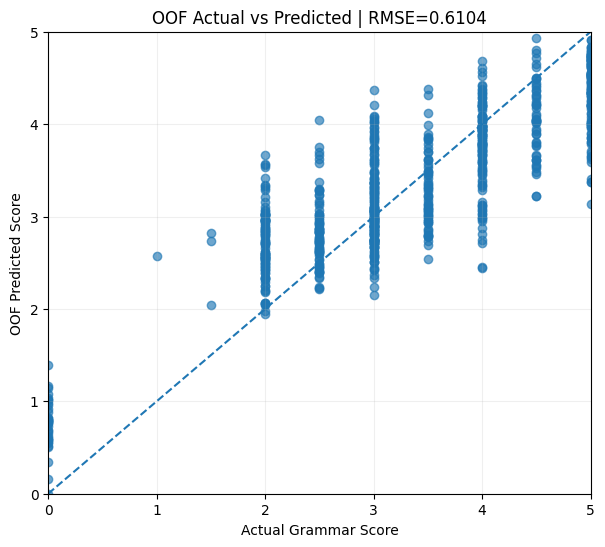

In [153]:
# ============================================================
# Cell 23 — Actual vs OOF prediction
# ============================================================

plt.figure(figsize=(7, 6))

plt.scatter(
    y,
    final_oof,
    alpha=0.65
)

plt.plot(
    [0, 5],
    [0, 5],
    linestyle="--"
)

plt.xlabel("Actual Grammar Score")
plt.ylabel("OOF Predicted Score")
plt.title(
    f"OOF Actual vs Predicted | RMSE={train_rmse:.4f}"
)

plt.xlim(0, 5)
plt.ylim(0, 5)
plt.grid(alpha=0.2)
plt.show()

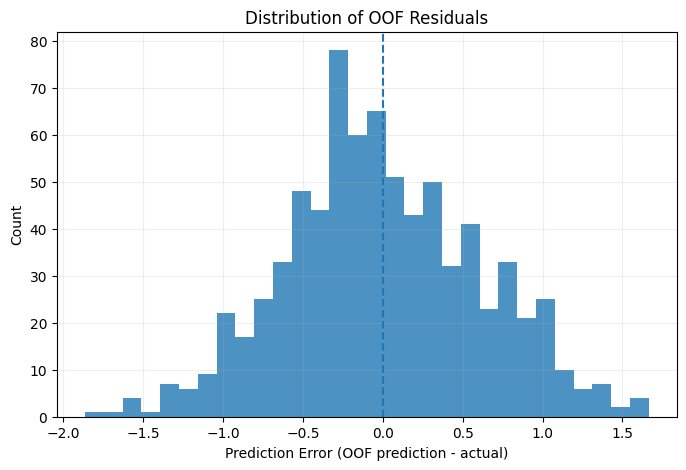

In [154]:
# ============================================================
# Cell 24 — OOF residual distribution
# ============================================================

residuals = final_oof - y

plt.figure(figsize=(8, 5))

plt.hist(
    residuals,
    bins=30,
    alpha=0.8
)

plt.axvline(
    0,
    linestyle="--"
)

plt.xlabel("Prediction Error (OOF prediction - actual)")
plt.ylabel("Count")
plt.title("Distribution of OOF Residuals")
plt.grid(alpha=0.2)
plt.show()

## 15. Final Kaggle Submission

### Submission format

My latest Kaggle submission achieved a score of **0.3437**.

For the final submission, I read the required column names directly from `sample_submission.csv`.

I keep the prediction rows in the exact order of `test.csv`, which contains the 216 evaluation audio files.

Before creating the final submission file, I validate:

- 216 rows
- exact two-column submission schema
- exact `test.csv` filename order
- no missing or infinite predictions
- every prediction is within `[0, 5]`


In [155]:
# ============================================================
# Cell 25 — Create and validate my final Kaggle submission
# ============================================================

# I take the required column names directly from the official
# sample submission instead of hard-coding "score".

submission_columns = list(sample_submission.columns)

assert len(submission_columns) == 2, (
    "sample_submission.csv must contain exactly two columns."
)

filename_column = submission_columns[0]
target_column = submission_columns[1]

submission = pd.DataFrame({
    filename_column: test_df["filename"].astype(str).to_numpy(),
    target_column: final_pred.astype(float)
})

submission_path = CACHE_DIR / "submission_final.csv"

submission.to_csv(
    submission_path,
    index=False
)

# ------------------------------------------------------------
# Validate the exact submission structure
# ------------------------------------------------------------

assert submission.shape == (216, 2)
assert submission.columns.tolist() == submission_columns

assert submission[filename_column].tolist() == (
    test_df["filename"].astype(str).tolist()
)

assert submission[target_column].notna().all()

assert np.isfinite(
    submission[target_column].to_numpy()
).all()

assert submission[target_column].between(
    0, 5
).all()

print("Expected columns:", submission_columns)
print("Actual columns  :", submission.columns.tolist())
print("Submission shape:", submission.shape)
print()
print(submission.head(10))
print()
print("Submission file:", submission_path)
print()
print("✓ Final submission format validated.")


Expected columns: ['filename', 'label']
Actual columns  : ['filename', 'label']
Submission shape: (216, 2)

        filename     label
0  audio_128.wav  3.200161
1  audio_156.wav  3.750547
2   audio_19.wav  4.474776
3  audio_108.wav  2.306917
4  audio_206.wav  2.703465
5  audio_161.wav  2.828509
6  audio_215.wav  2.944105
7  audio_213.wav  2.575800
8   audio_11.wav  3.615102
9  audio_155.wav  3.139493

Submission file: /kaggle/working/submission_final.csv

✓ Final submission format validated.


## 16. Final Report

### What I built

I built a multi-modal regression pipeline for spoken grammar scoring. I combine audio representations, transcripts, acoustic information, explicit grammar features, and Whisper quality/timing features.

### Feature groups

| Feature group | Features |
|---|---:|
| Deep representation | 7,424 |
| Acoustic | 37 |
| Grammar/Text | 21 |
| Whisper quality | 10 |
| Rich LightGBM input | 68 |
| ExtraTrees compact branch | 47 |

### My model pipeline

**Audio → speech representations**

**Audio → Whisper transcript → text representations + grammar features**

**Audio → acoustic + Whisper quality features**

These branches are combined using Ridge, ExtraTrees, residual correction, and LightGBM models.

### Evaluation

I report OOF RMSE and Pearson correlation on the training data. I use OOF predictions for the main validation result instead of presenting only an optimistic in-sample score.

### My benchmark

My uploaded `previous benchmark CSV` is the benchmark submission that gave me **0.3437 on the leaderboard**. I keep it as a reference, but I do not claim that this newly reconstructed pipeline will automatically reproduce 0.3437 without another Kaggle submission.

### Final output

My notebook creates:

`/kaggle/working/submission_final.csv`

The final validation checks the row count, the exact sample-submission column names, test filename order, finite numeric values, and the valid score range.


In [156]:
# ============================================================
# Cell 26 — My final notebook summary
# ============================================================

print("=" * 72)
print("SHL HIRING ASSESSMENT 2026 — MY FINAL SUMMARY")
print("=" * 72)

print(f"Train rows              : {len(train_df)}")
print(f"Test rows               : {len(test_df)}")
print(f"Deep representation     : {deep_train.shape[1]} features")
print(f"Acoustic features       : {X_acoustic_train.shape[1]}")
print(f"Grammar features        : {X_grammar_train.shape[1]}")
print(f"Whisper quality         : {X_quality_train.shape[1]}")
print(f"ExtraTrees features     : {X_et_train.shape[1]}")
print(f"LightGBM features       : {X_lgb_train.shape[1]}")
print(f"Required OOF RMSE       : {train_rmse:.6f}")
print(f"OOF Pearson             : {train_pearson:.6f}")
print(f"Submission rows         : {len(submission)}")
print(f"Submission columns      : {list(submission.columns)}")
print(f"Submission path         : {submission_path}")

print("=" * 72)
print("✓ My final notebook pipeline completed.")


SHL HIRING ASSESSMENT 2026 — MY FINAL SUMMARY
Train rows              : 769
Test rows               : 216
Deep representation     : 7424 features
Acoustic features       : 37
Grammar features        : 21
Whisper quality         : 10
ExtraTrees features     : 47
LightGBM features       : 68
Required OOF RMSE       : 0.610368
OOF Pearson             : 0.883011
Submission rows         : 216
Submission columns      : ['filename', 'label']
Submission path         : /kaggle/working/submission_final.csv
✓ My final notebook pipeline completed.
